## 1. Khởi tạo Spark

In [1]:
import os, sys, time

os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
os.environ["PYSPARK_PYTHON"] = sys.executable
# Spark trên Windows cần hadoop.dll trong PATH để ghi file
os.environ["PATH"] = os.path.join(os.environ.get("HADOOP_HOME", r"C:\hadoop"), "bin") + os.pathsep + os.environ["PATH"]

import pandas as pd
from pyspark.sql import SparkSession, functions as F
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor, GBTRegressor

spark = (SparkSession.builder
         .master("local[*]")
         .appName("RussiaRealEstateModeling")
         .config("spark.driver.memory", "8g")
         .config("spark.sql.shuffle.partitions", "16")
         .getOrCreate())
spark.version

'3.5.3'

## 2. Đọc dữ liệu

Tập train là toàn bộ `train_model.parquet`; tập test là toàn bộ `test_model.parquet` (2 tháng đầu sau giai đoạn train, 02/05–30/06/2021, đã bỏ bản ghi trùng với tập train).

In [2]:
train = spark.read.parquet("../data/train_model.parquet")
test = spark.read.parquet("../data/test_model.parquet")
print(f"Train: {train.count():,} bản ghi | Test: {test.count():,} bản ghi")

Train: 5,459,594 bản ghi | Test: 1,572,995 bản ghi


## 3. Chuẩn bị đặc trưng


In [3]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder

TARGET_LOG = True
NUMERIC = [c for c in train.columns if c not in ("price", "province")]
FEATURES = NUMERIC + ["province_idx"]
label = F.log("price") if TARGET_LOG else F.col("price").cast("double")
# frequencyAsc xếp tỉnh nhiều bản ghi nhất cuối cùng để OneHotEncoder bỏ đi làm nhóm tham chiếu
encode = Pipeline(stages=[
    StringIndexer(inputCol="province", outputCol="province_idx", stringOrderType="frequencyAsc"),
    OneHotEncoder(inputCols=["province_idx"], outputCols=["province_ohe"]),
]).fit(train)

def vectorize(features):
    """Vector `features` cho RF, GBT và `features_lr` cho LR (one-hot `province`, bỏ `is_moscow_or_spb`); trả về train, test đã cache."""
    lr_features = ["province_ohe" if c == "province_idx" else c for c in features if c != "is_moscow_or_spb"]
    assemble = Pipeline(stages=[encode, VectorAssembler(inputCols=features, outputCol="features"),
                                VectorAssembler(inputCols=lr_features, outputCol="features_lr")]).fit(train)
    train_vec = assemble.transform(train).withColumn("label", label).select("features", "features_lr", "label").cache()
    test_vec = (assemble.transform(test).withColumn("label", label)
                        .select("price", "province", "features", "features_lr", "label").cache())
    return train_vec, test_vec

train_vec, test_vec = vectorize(FEATURES)
print(f"{len(FEATURES)} đặc trưng cho RF và GBT:", FEATURES)
print(f"Đã cache: train {train_vec.count():,} | test {test_vec.count():,}")

17 đặc trưng cho RF và GBT: ['geo_lat', 'geo_lon', 'distance_to_capital', 'area', 'rooms', 'is_studio', 'level', 'level_ratio', 'pre_owned_house', 'months_since_start', 'is_moscow_or_spb', 'bt_block', 'bt_brick', 'bt_monolithic', 'bt_others', 'bt_wooden', 'province_idx']
Đã cache: train 5,459,594 | test 1,572,995


## 4. Huấn luyện và đánh giá


In [4]:
METRIC_FMT = {"R2": "{:.4f}", "MAE": "{:,.0f}", "MAPE (%)": "{:.2f}", "Thời gian huấn luyện (s)": "{:.0f}"}

def evaluate(pred):
    p = pred.withColumn("pred_price", F.exp("prediction") if TARGET_LOG else F.col("prediction"))
    err = F.col("price") - F.col("pred_price")
    r = p.agg(F.avg(F.abs(err)).alias("MAE"),
              (100 * F.avg(F.abs(err) / F.col("price"))).alias("MAPE"),
              F.sum((F.log("price") - F.log("pred_price")) ** 2).alias("ss_res"),
              F.avg(F.log("price")).alias("mean_log")).first()
    ss_tot = p.agg(F.sum((F.log("price") - F.lit(r["mean_log"])) ** 2)).first()[0]
    return {"R2": 1 - r["ss_res"] / ss_tot, "MAE": r["MAE"], "MAPE (%)": r["MAPE"]}

Huấn luyện Linear Regression, Random Forest và GBT trên toàn bộ tập train 

In [5]:
models = {
    "Linear Regression": LinearRegression(featuresCol="features_lr", labelCol="label"),
    "Random Forest": RandomForestRegressor(featuresCol="features", labelCol="label", numTrees=30, maxDepth=10, maxBins=128, seed=42),
    "GBT": GBTRegressor(featuresCol="features", labelCol="label", maxIter=30, maxDepth=6, maxBins=128, seed=42),
}

def train_and_evaluate(train_vec, test_vec, names=tuple(models)):
    """Huấn luyện các mô hình trong `names` trên train_vec, đánh giá trên test_vec; trả về bảng metric và các mô hình đã huấn luyện."""
    results, fitted = {}, {}
    for name in names:
        t0 = time.time()
        fitted[name] = models[name].fit(train_vec)
        fit_time = time.time() - t0
        results[name] = {**evaluate(fitted[name].transform(test_vec)), "Thời gian huấn luyện (s)": fit_time}
        print(f"{name}: xong sau {fit_time:.0f}s")
    return pd.DataFrame(results).T, fitted

metrics, fitted = train_and_evaluate(train_vec, test_vec)
metrics.style.format(METRIC_FMT)

Linear Regression: xong sau 11s
Random Forest: xong sau 592s
GBT: xong sau 350s


,R2,MAE,MAPE (%),Thời gian huấn luyện (s)
Linear Regression,0.5551,"1,880,052",31.98,11
Random Forest,0.7877,"1,541,011",24.42,592
GBT,0.8461,"1,311,895",21.58,350


## 5. Độ quan trọng đặc trưng

Độ quan trọng (`featureImportances`) của Random Forest và GBT đã huấn luyện ở trên, xếp theo GBT.

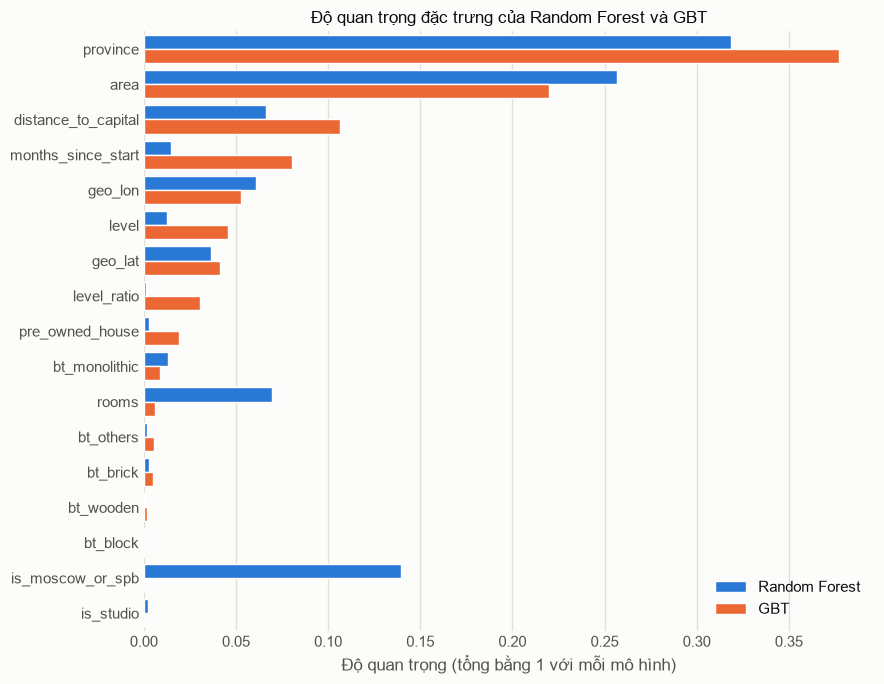

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="white", rc={
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "grid.color": "#e1e0d9",
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
})
importance = (pd.DataFrame({name: fitted[name].featureImportances.toArray() for name in ["Random Forest", "GBT"]},
                           index=[f.removesuffix("_idx") for f in FEATURES])
                .sort_values("GBT", ascending=False))
imp_long = importance.rename_axis("feature").reset_index().melt(id_vars="feature", var_name="model", value_name="importance")

fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(data=imp_long, x="importance", y="feature", hue="model", hue_order=["Random Forest", "GBT"],
            palette={"Random Forest": "#2a78d6", "GBT": "#eb6834"}, saturation=1, ax=ax)
ax.set(xlabel="Độ quan trọng (tổng bằng 1 với mỗi mô hình)", ylabel=None, title="Độ quan trọng đặc trưng của Random Forest và GBT")
ax.legend(title=None, frameon=False, loc="lower right")
ax.grid(axis="x", linewidth=1)
ax.set_axisbelow(True)
ax.tick_params(length=0)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

## 6. Rút gọn đặc trưng

Bỏ các đặc trưng có độ quan trọng dưới 1% trong GBT, mô hình tốt nhất ở mục 4.

In [ ]:
THRESHOLD = 0.01
dropped = importance.index[importance["GBT"] < THRESHOLD].tolist()
REDUCED = [f for f in FEATURES if f.removesuffix("_idx") not in dropped]
print(f"Bỏ {len(dropped)} đặc trưng:", dropped)
print(f"Giữ {len(REDUCED)} đặc trưng:", REDUCED)

Bỏ 8 đặc trưng: ['bt_monolithic', 'rooms', 'bt_others', 'bt_brick', 'bt_wooden', 'bt_block', 'is_moscow_or_spb', 'is_studio']
Giữ 9 đặc trưng: ['geo_lat', 'geo_lon', 'distance_to_capital', 'area', 'level', 'level_ratio', 'pre_owned_house', 'months_since_start', 'province_idx']


## 7. Huấn luyện lại GBT trên bộ đặc trưng rút gọn

Huấn luyện lại GBT với cùng tham số như mục 4 trên bộ đặc trưng rút gọn rồi đánh giá trên tập test.

In [ ]:
train_vec.unpersist()  # giải phóng bộ nhớ của bộ đặc trưng đầy đủ
test_vec.unpersist()
train_red, test_red = vectorize(REDUCED)
metrics_red, fitted_red = train_and_evaluate(train_red, test_red, ["GBT"])

So sánh R², MAE, MAPE và thời gian huấn luyện của GBT trên bộ đặc trưng đầy đủ và rút gọn.

In [ ]:
comparison = pd.DataFrame({f"Đầy đủ ({len(FEATURES)})": metrics.loc["GBT"],
                           f"Rút gọn ({len(REDUCED)})": metrics_red.loc["GBT"]}).T
comparison.style.format(METRIC_FMT)

,R2,MAE,MAPE (%),Thời gian huấn luyện (s)
Đầy đủ (17),0.8461,"1,311,895",21.58,421
Rút gọn (9),0.8553,"1,280,573",20.98,388


## 8. Phân phối sai số

Histogram sai số tương đối (dự đoán/thực − 1) của GBT rút gọn trên toàn bộ tập test, giá trị âm là đoán thấp hơn giá thực.

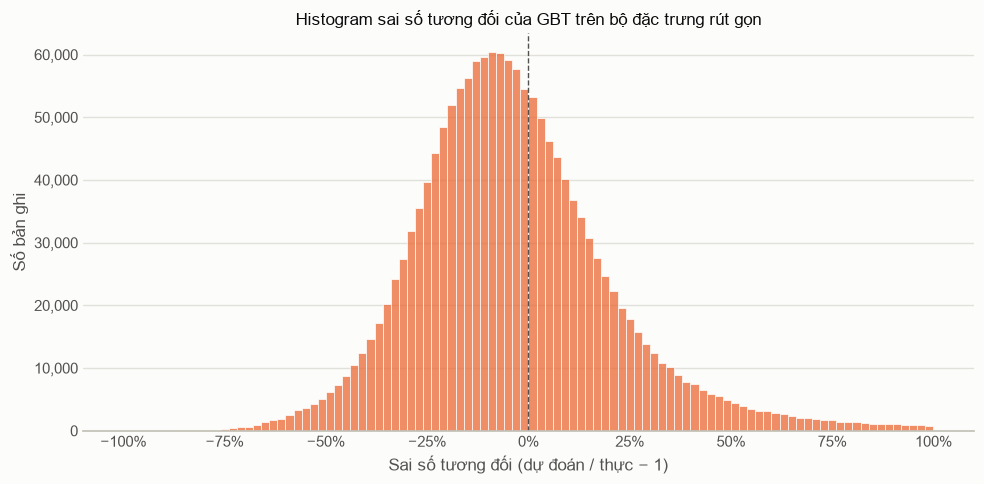

In [16]:
from matplotlib.ticker import FuncFormatter, PercentFormatter

pred_price = F.exp("prediction") if TARGET_LOG else F.col("prediction")
error_pct = (fitted_red["GBT"].transform(test_red)
             .select((100 * (pred_price / F.col("price") - 1)).alias("error_pct")).toPandas()["error_pct"])

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(x=error_pct, binrange=(-100, 100), binwidth=2, color="#eb6834", ax=ax)
ax.axvline(0, color="#52514e", linestyle="--", linewidth=1)
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.set(xlabel="Sai số tương đối (dự đoán / thực − 1)", ylabel="Số bản ghi",
       title="Histogram sai số tương đối của GBT trên bộ đặc trưng rút gọn")
ax.grid(axis="y", linewidth=1)
ax.set_axisbelow(True)
ax.tick_params(length=0)
sns.despine(left=True)
plt.tight_layout()
plt.show()

PbAPE của GBT rút gọn với bước 10%: tỉ lệ bản ghi có sai số phần trăm tuyệt đối không vượt quá từng mức.

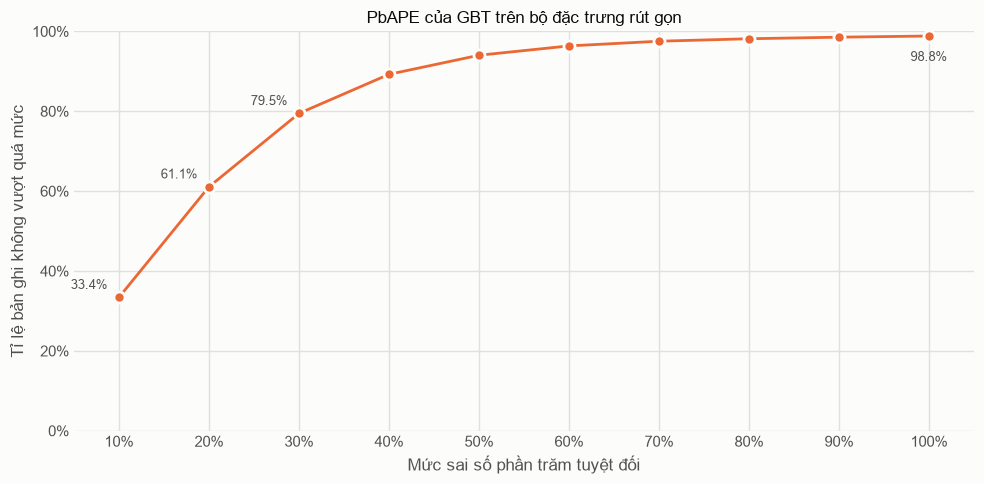

≤ 10%     33.40%
≤ 20%     61.08%
≤ 30%     79.45%
≤ 40%     89.23%
≤ 50%     94.01%
≤ 60%     96.35%
≤ 70%     97.53%
≤ 80%     98.15%
≤ 90%     98.54%
≤ 100%    98.83%


In [15]:
steps = list(range(10, 101, 10))
pbape = pd.Series([100 * (error_pct.abs() <= t).mean() for t in steps], index=steps)

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(x=pbape.index, y=pbape.values, color="#eb6834", linewidth=2, marker="o", markersize=8,
             markeredgecolor="#fcfcfb", markeredgewidth=2, ax=ax)
for t in (10, 20, 30, 100):
    above = pbape[t] < 90  # điểm cao sát 100% thì ghi nhãn bên dưới
    ax.annotate(f"{pbape[t]:.1f}%", (t, pbape[t]), textcoords="offset points", xytext=(-8, 6) if above else (0, -18),
                ha="right" if above else "center", color="#52514e", fontsize=9)
ax.set(xticks=steps, xlim=(5, 105), ylim=(0, 100), xlabel="Mức sai số phần trăm tuyệt đối",
       ylabel="Tỉ lệ bản ghi không vượt quá mức", title="PbAPE của GBT trên bộ đặc trưng rút gọn")
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.grid(linewidth=1)
ax.set_axisbelow(True)
ax.tick_params(length=0)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()
print(pbape.rename(lambda t: f"≤ {t}%").map("{:.2f}%".format).to_string())